# Optimizer example

Same data and model as `grid_example.ipynb`, fitted with a minimizer instead of a grid.

`fit_optimizer` needs:

- `residuals(theta)`: model − data on the fitted pixels;
- `minimize(objective, theta_start)`: any minimizer that returns the best `theta`.

Each grid operation becomes a refit:

- `sigma_sys` and the fit are iterated until both converge.
- Stat errors come from the curvature of `χ²_eff` or from a profile scan.
- Each leave-one-out and bootstrap replicate is refitted.

In [1]:
import sys
sys.path.insert(0, '..')   # or install the package: pip install -e ..
import numpy as np
import matplotlib.pyplot as plt
import wellfit as wf
import toy_lines as tl     # toy broadening model + synthetic data for these examples
%matplotlib inline
from scipy.optimize import minimize

## 1. Data

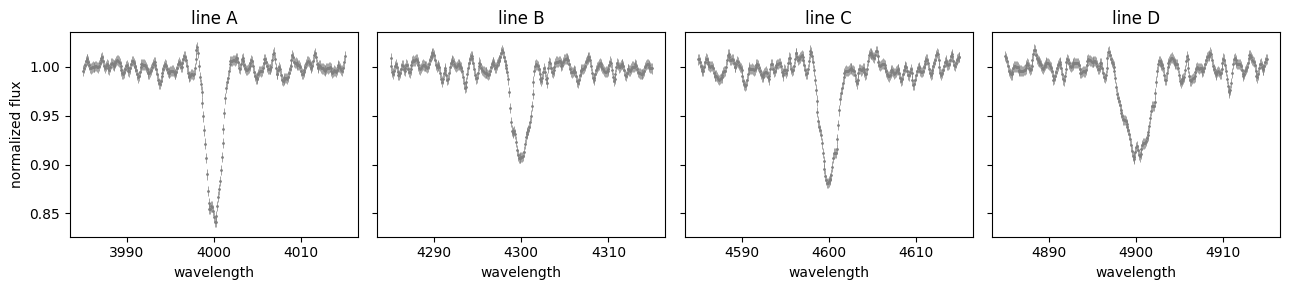

In [2]:
# Select a set of "true" parameters for the synthetic data
TRUTH = dict(vsini=100., vmacro=10., vsini_D=140., snr=150.)

# Generate synthetic data with the above parameters
d = tl.make_data(**TRUTH)
lam_obs, flux_obs, err_obs, groups, names = d['lam'], d['flux'], d['err'], d['groups'], d['names']

# Plot the synthetic data
fig, axs = plt.subplots(1, 4, figsize=(13, 3), sharey=True)
for j, ax in enumerate(axs):
    m = groups == j
    ax.errorbar(lam_obs[m], flux_obs[m], err_obs[m], fmt='.', ms=2, color='0.5', lw=0.5)
    ax.set_title(f'line {names[j]}'); ax.set_xlabel('wavelength')
axs[0].set_ylabel('normalized flux'); plt.tight_layout()

## 2. Noise

Both quantities are measured in the line-free continuum next to each line (`d['ref_ranges']`), with a constant
baseline (`deg=0`).

- `measure_error_scale`: the factor that brings the continuum scatter to unit width (expected ≈ 1.25).
- `measure_n_corr`: the number of correlated pixels (expected ≈ 5). Short continuum segments bias it slightly low.

error scale factor = 1.26   (injected 1 / 0.8 = 1.25)


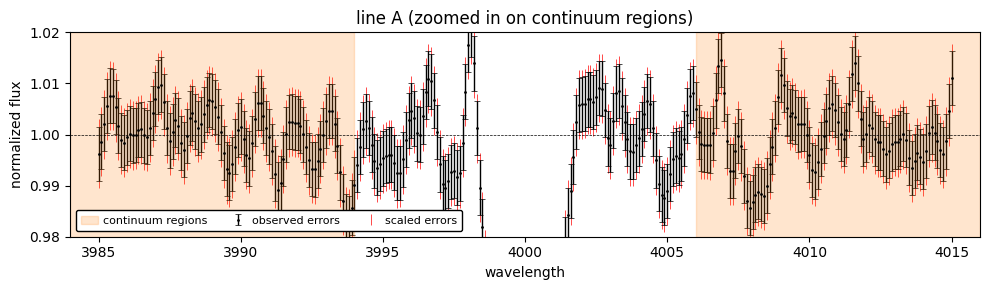

In [3]:
# Measure the error scale factor (i.e., how much the observed errors need to be scaled to match the actual scatter)
err_obs_scaled, factor = wf.measure_error_scale(lam_obs, flux_obs, err_obs, d['ref_ranges'], deg=0)
print(f"error scale factor = {factor:.2f}   (injected 1 / 0.8 = 1.25)")

# Plot the measured error scale factor for one of the lines, zoomed in on continuum regions
fig, ax = plt.subplots(1, 1, figsize=(10, 3))
m = groups == 0
ax.errorbar(lam_obs[m], flux_obs[m], err_obs[m], fmt='.', ms=2, color='k', lw=1, zorder=1, capthick=0.5, capsize=2, label='observed errors')
# Scale the errors by the measured factor to show that the scatter is now consistent with the errors
ax.errorbar(lam_obs[m], flux_obs[m], err_obs[m] * factor, fmt='None', ms=2, color='red', lw=0.5, zorder=0, label='scaled errors')
ax.set_title(f'line {names[0]} (zoomed in on continuum regions)'); ax.set_xlabel('wavelength'); ax.set_ylabel('normalized flux')
for j in range(2):
    ax.axvspan(d['ref_ranges'][j][0], d['ref_ranges'][j][1], color='C1', alpha=0.2, label='continuum regions' if j == 0 else None)
ax.set_xlim(d['ref_ranges'][0][0], d['ref_ranges'][1][1]); plt.tight_layout()
ax.axhline(1, color='k', ls='--', lw=0.5)
ax.set_ylim(0.98, 1.02)
ax.legend(loc='lower left', fontsize=8, frameon=True, 
          framealpha=1, fancybox=True, edgecolor='k', facecolor='w', handlelength=1.5, handletextpad=0.5, borderpad=0.5, ncol=3)
plt.tight_layout()

In [4]:
# Measure the number of correlated pixels and the correlation coefficients
n_corr, rho = wf.measure_n_corr(lam_obs, flux_obs, err_obs, d['ref_ranges'], deg=0)
print(f"n_corr = {n_corr:.2f}   (injected {d['truth']['n_corr']:.2f}); rho_1..4 = {np.round(rho[:4], 2)}")
print(f"{lam_obs.size} pixels -> {lam_obs.size / n_corr:.0f} independent pixels")

n_corr = 4.94   (injected 5.32); rho_1..4 = [0.88 0.62 0.34 0.13]
1204 pixels -> 244 independent pixels


## 3. Model and minimizer

The minimizer is bounded at 0. The model has to be smooth in its parameters for the finite-difference curvature to
work, which is why `toy_lines` applies its kernels analytically in Fourier space.

In [5]:
def residuals(theta, m=slice(None)):
    vsini, vmacro = theta
    return tl.model(lam_obs[m], groups[m], vsini, vmacro) - flux_obs[m]

def nelder_mead(objective, theta_start):
    # bounds sized from theta_start: the profile scans call this with the scanned parameter removed
    return minimize(objective, theta_start, method='Nelder-Mead', bounds=[(0, 400)] * len(theta_start),
                    options={'xatol': 1e-3, 'fatol': 1e-6}).x

theta0 = [50., 30.]

## 4. Naive fit vs `wellfit`

The naive fit uses `err_obs`, `n_corr = 1` and no systematic floor.

For `wellfit` we also request profile scans (`profile=`). At each value of one parameter the other is refitted, and the
errors are read where Δχ²_eff = 1. Unlike curvature errors, these are asymmetric and valid next to a bound such as
`vmacro = 0`.

In [6]:
naive = wf.fit_optimizer(residuals, nelder_mead, theta0, err_obs, n_corr=1., fit_sigma_sys=False,
                         param_names=['vsini', 'vmacro'])
fit = wf.fit_optimizer(residuals, nelder_mead, theta0, err_obs_scaled, n_corr, groups=groups, group_names=names,
                       param_names=['vsini', 'vmacro'], n_boot=100,
                       profile={'vsini': np.arange(60, 160.1, 1.), 'vmacro': np.arange(0, 60.1, 1.)})

print(f"naive: chi2 = {naive.chi2:.0f} for {naive.nu:.0f} dof (reduced chi2 = {naive.chi2 / naive.nu:.1f})")
for k, (v, ep, em, _, _) in naive.results.items():
    print(f"  {k:7s} = {v:6.1f} +{ep:.1f} -{em:.1f}")
print()
print(fit.summary())
print("\ncurvature (Hessian) errors for comparison:", dict(zip(fit.param_names, np.sqrt(np.diag(fit.cov)).round(1))))

naive: chi2 = 2886 for 1202 dof (reduced chi2 = 2.4)
  vsini   =  106.0 +1.1 -1.1
  vmacro  =   22.6 +1.5 -1.5

n_data = 1204, n_corr = 4.94 -> 243.8 independent points, nu = 241.8
sigma_sys = 0.004857; best fit: chi2 = 1818.0 (raw), chi2_eff = 241.8
Parameters (value +stat -stat, +sys -sys):
  vsini             106  +3.524 -4.268   sys +10.34 -5.175
  vmacro          22.62  +5.439 -5.359   sys +6.127 -9.229
Groups (chi2_eff / expected, tension, leave-one-out best vsini, vmacro):
  A                0            41.5 /   60.9  tension    5.5  109.3  28.27
  B                0            43.6 /   60.9  tension    0.5  105.2  25.84
  C                0            57.2 /   60.9  tension    2.5  109.9  23.36
  D                0            99.5 /   60.9  tension   19.5  100.8  12.23

curvature (Hessian) errors for comparison: {'vsini': 3.8, 'vmacro': 5.3}


## 5. Profiles

The profiled `χ²_eff` (solid) against the curvature approximation (dashed). The dotted line marks Δχ²_eff = 1. Where
the two differ, use the profile.

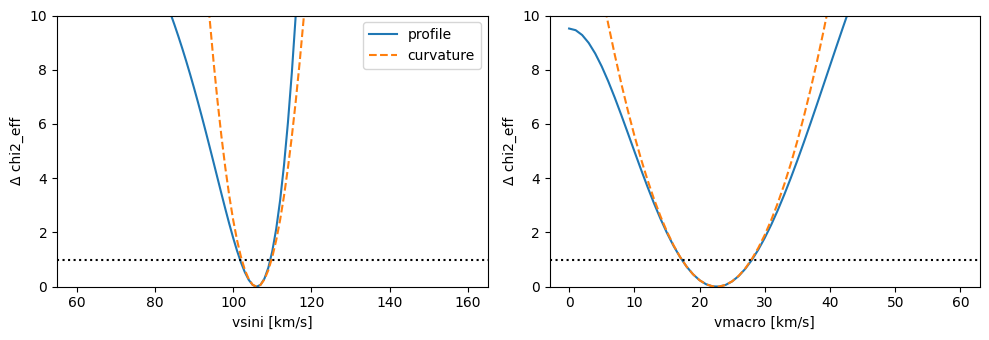

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, (k, (vals, prof)) in zip(axs, fit.profiles.items()):
    i = fit.param_names.index(k)
    ax.plot(vals, prof - fit.chi2_eff, 'C0', label='profile')
    ax.plot(vals, (vals - fit.theta[i])**2 / fit.cov[i, i], 'C1--', label='curvature')
    ax.axhline(1, color='k', ls=':')
    ax.set_ylim(0, 10); ax.set_xlabel(f'{k} [km/s]'); ax.set_ylabel('Δ chi2_eff')
axs[0].legend(); plt.tight_layout()

## 6. Tension

As in the grid example, line D has a large tension, so we refit with lines A–C only.

Refits start from the best fit, and they can get stuck along the `vsini`–`vmacro` degeneracy or at a bound. If the
results look odd, try several values of `theta0` or compare with the grid.

n_data = 903, n_corr = 4.94 -> 182.8 independent points, nu = 180.8
sigma_sys = 0.001232; best fit: chi2 = 923.1 (raw), chi2_eff = 180.8
Parameters (value +stat -stat, +sys -sys):
  vsini           100.8  +2.299 -2.561   sys +3.097 -2.85
  vmacro          12.23  +4.783 -5.881   sys +3.068 -5.087
Groups (chi2_eff / expected, tension, leave-one-out best vsini, vmacro):
  A                0            48.1 /   60.9  tension    0.4  102.3  6.9
  B                0            60.9 /   60.9  tension    0.7  98.54  15.2
  C                0            71.8 /   60.9  tension    0.4  102.5  10.89


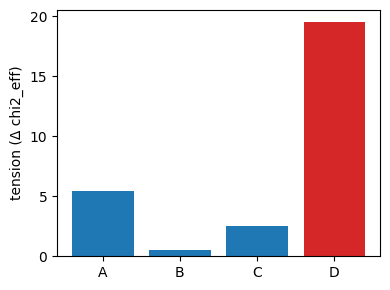

In [8]:
fig, ax = plt.subplots(figsize=(4, 3))
ax.bar(names, fit.tension, color=['C0'] * 3 + ['C3'])
ax.set_ylabel('tension (Δ chi2_eff)'); plt.tight_layout()

keep = groups != names.index('D')
fit_noD = wf.fit_optimizer(lambda th: residuals(th, keep), nelder_mead, fit.theta, err_obs_scaled[keep], n_corr,
                           groups=groups[keep], group_names=names[:3], param_names=['vsini', 'vmacro'], n_boot=100,
                           profile={'vsini': np.arange(60, 160.1, 1.), 'vmacro': np.arange(0, 60.1, 1.)})
print(fit_noD.summary())

## 7. 2D posterior: lines A–D vs A–C

This is the same plot as in the grid example, plus the curvature ellipses (dashed, from `fit.cov`). The ellipses get
the core and the tilt right, but miss the tail toward low `vsini` and high `vmacro`; that tail is why the profile
errors are asymmetric. The posterior is evaluated on a mesh for display only. With more than about three parameters,
use MCMC (`mcmc_example.ipynb`).

- **Lines A–D:** the posterior is biased. The bootstrap points scatter far outside the contours, so the sys error
  exceeds the stat error, and `sigma_sys` is large.
- **Lines A–C:** `sigma_sys` drops by about 4×. The contours shrink and contain the truth, and the bootstrap points fall
  inside them (sys ≈ stat).

Tension shows which line to inspect. Remove a line only for a physical reason, not because of its tension alone.

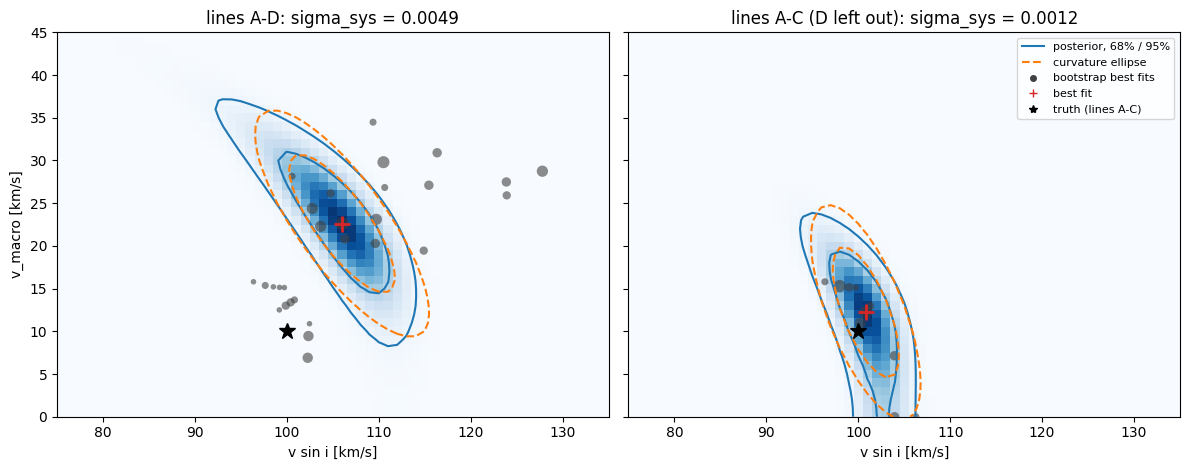

In [9]:
def plot_post2d(ax, d2, x, y, best, boot=None, d2_curv=None, title=''):
    # posterior exp(-Delta chi2_eff / 2) on the (y, x) mesh, its 68% / 95% contours (2 parameters), the curvature
    # ellipses, and the bootstrap best fits (marker size = number of replicates at that point)
    ax.pcolormesh(x, y, np.exp(-0.5 * d2), cmap='Blues', shading='auto')
    ax.contour(x, y, d2, levels=[2.30, 6.18], colors='C0', linestyles='-')
    if d2_curv is not None:
        ax.contour(x, y, d2_curv, levels=[2.30, 6.18], colors='C1', linestyles='--')
    if boot is not None:
        pts, n = np.unique(np.round(boot, 4), axis=0, return_counts=True)
        ax.scatter(*pts.T, s=6 + 80 * n / n.max(), color='0.25', alpha=0.6, lw=0)
    ax.plot(*best, 'C3+', ms=12, mew=2)
    ax.plot(TRUTH['vsini'], TRUTH['vmacro'], 'k*', ms=12)
    ax.set_xlim(x[0], x[-1]); ax.set_ylim(y[0], y[-1])
    ax.set_title(title); ax.set_xlabel('v sin i [km/s]')

def legend2d(ax, ellipse=False):
    items = [('posterior, 68% / 95%', dict(color='C0'))]
    items += [('curvature ellipse', dict(color='C1', ls='--'))] if ellipse else []
    items += [('bootstrap best fits', dict(color='0.25', marker='o', ms=4, ls='')),
              ('best fit', dict(color='C3', marker='+', ls='')), ('truth (lines A-C)', dict(color='k', marker='*', ls=''))]
    for lab, kw in items:
        ax.plot([], [], label=lab, **kw)
    ax.legend(fontsize=8, loc='upper right')

vs_mesh, vm_mesh = np.linspace(75, 135, 61), np.linspace(0, 45, 46)
A, B = np.meshgrid(vs_mesh, vm_mesh)

def mesh_dchi2(f, m=slice(None)):
    c2 = np.array([[wf.chi2_eff(residuals([a, b], m), err_obs_scaled[m], n_corr, f.sigma_sys) for a in vs_mesh] for b in vm_mesh])
    dx = np.stack([A - f.theta[0], B - f.theta[1]], axis=-1)
    return c2 - min(c2.min(), f.chi2_eff), np.einsum('...i,ij,...j->...', dx, np.linalg.inv(f.cov), dx)

fig, axs = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
for ax, f, m, t in [(axs[0], fit, slice(None), 'lines A-D'), (axs[1], fit_noD, keep, 'lines A-C (D left out)')]:
    d2, d2_curv = mesh_dchi2(f, m)
    plot_post2d(ax, d2, vs_mesh, vm_mesh, f.theta, boot=f.theta_boot, d2_curv=d2_curv,
                title=f"{t}: sigma_sys = {f.sigma_sys:.4f}")
axs[0].set_ylabel('v_macro [km/s]'); legend2d(axs[1], ellipse=True); plt.tight_layout()

## MCMC

Use `wf.log_likelihood(residuals(theta), err_obs_scaled, n_corr, fit.sigma_sys)` as the likelihood; it equals
−χ²_eff/2 + const. See `mcmc_example.ipynb`.